# Multi-Label Emotion Detection Using NLP

This notebook demonstrates the process of training models to detect multiple emotions in text.

## Overview
1. Data loading and exploration
2. Emotion distribution analysis
3. Text preprocessing
4. Traditional ML approach with Naive Bayes
5. Deep learning approach with BERT
6. Model evaluation and saving

In [71]:
import os
import re
from datasets import Dataset
from sklearn.preprocessing import MultiLabelBinarizer

import string
import emoji

# Import necessary libraries
import matplotlib.pyplot as plt
import nltk
import numpy as np  # noqa:
import pandas as pd
import seaborn as sns
import torch
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import hamming_loss
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression
from transformers import (AutoTokenizer, BertTokenizer, AutoModelForSequenceClassification,
                          BertForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

In [72]:
# Download necessary NLTK resources
nltk.download('punkt');
nltk.download('wordnet');
nltk.download('stopwords');
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [73]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cpu


## 1. Data Loading and Initial Exploration

In [74]:
# Load the dataset
df = pd.read_csv(r"data/main.csv")

# Display the first few rows to understand the data structure
df.head()

,id,text,anger,fear,joy,sadness,surprise
0,eng_train_track_a_00001,"Colorado, middle of nowhere.",0,1,0,0,1
1,eng_train_track_a_00002,This involved swimming a pretty large lake tha...,0,1,0,0,0
2,eng_train_track_a_00003,It was one of my most shameful experiences.,0,1,0,1,0
3,eng_train_track_a_00004,"After all, I had vegetables coming out my ears...",0,0,0,0,0
4,eng_train_track_a_00005,Then the screaming started.,0,1,0,1,1


## 2. Emotion Distribution Analysis

Understanding the distribution of emotions in our dataset is crucial for identifying potential class imbalance issues that might affect model training.

In [75]:
# Calculate absolute counts for each emotion
emotion_counts = {
    'anger': df['anger'].sum(),
    'fear': df['fear'].sum(),
    'joy': df['joy'].sum(),
    'sadness': df['sadness'].sum(),
    'surprise': df['surprise'].sum()
}

total_entries = len(df)

# Calculate percentage distribution
emotion_percentages = {emotion: (count / total_entries) * 100
                       for emotion, count in emotion_counts.items()}

# Display distribution statistics
print("Emotion Distribution Analysis")
print("=" * 30)
print(f"Total entries: {total_entries}\n")

print("Absolute counts:")
for emotion, count in emotion_counts.items():
    print(f"{emotion.capitalize()}: {count}")

print("\nPercentages:")
for emotion, percentage in emotion_percentages.items():
    print(f"{emotion.capitalize()}: {percentage:.2f}%")

Emotion Distribution Analysis
Total entries: 2768

Absolute counts:
Anger: 333
Fear: 1611
Joy: 674
Sadness: 878
Surprise: 839

Percentages:
Anger: 12.03%
Fear: 58.20%
Joy: 24.35%
Sadness: 31.72%
Surprise: 30.31%


/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_82544/3478685322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette='deep')


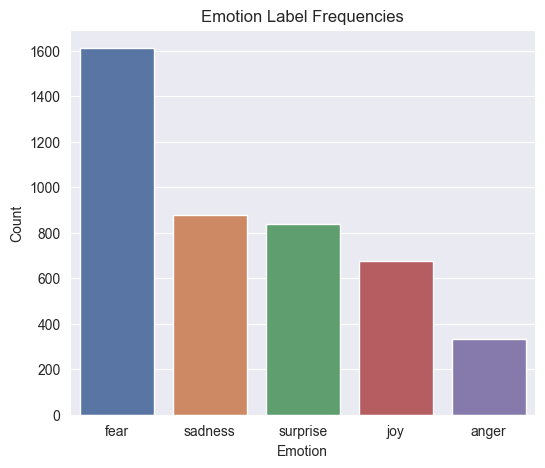

In [76]:
emotion_cols = ['anger', 'fear', 'joy', 'sadness', 'surprise']
label_counts = df[emotion_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(6, 5))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='deep')
plt.title("Emotion Label Frequencies")
plt.ylabel("Count")
plt.xlabel("Emotion")
plt.show()

/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_82544/2437962607.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=multilabel_sentences.index, y=multilabel_sentences.values, palette='deep')


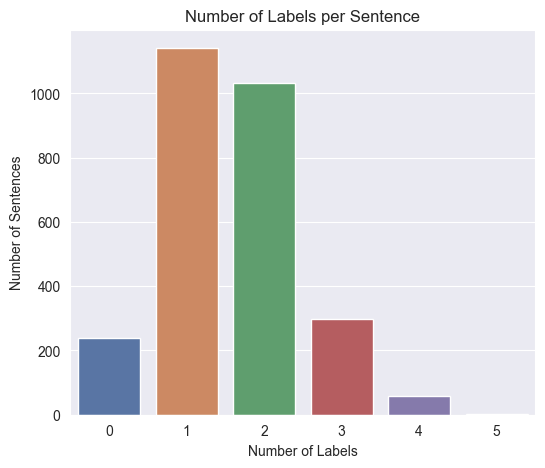

In [77]:
# Count how many labels each sentence has
df["num_labels"] = df[emotion_cols].sum(axis=1)
multilabel_sentences = df["num_labels"].value_counts().sort_index()

plt.figure(figsize=(6, 5))
sns.barplot(x=multilabel_sentences.index, y=multilabel_sentences.values, palette='deep')
plt.title("Number of Labels per Sentence")
plt.xlabel("Number of Labels")
plt.ylabel("Number of Sentences")
plt.show()

count    2768.000000
mean       15.477601
std        10.856667
min         1.000000
25%         8.000000
50%        13.000000
75%        20.000000
max        89.000000
Name: token_count, dtype: float64


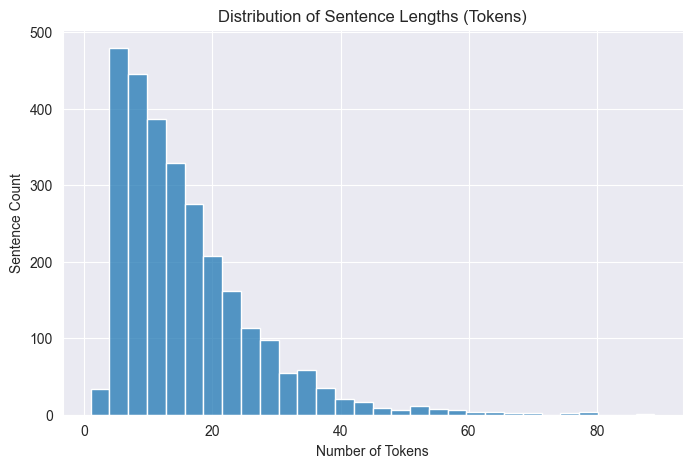

In [78]:
df["token_count"] = df["text"].apply(lambda x: len(str(x).split()))
print(df["token_count"].describe())

# Plot sentence length distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["token_count"], bins=30, kde=False)
plt.title("Distribution of Sentence Lengths (Tokens)")
plt.xlabel("Number of Tokens")
plt.ylabel("Sentence Count")
plt.show()

## 3. Text Preprocessing

We'll prepare the text data for modeling by:
- Converting to lowercase
- Tokenizing
- Removing punctuation and stopwords
- Stemming words to their root form

In [79]:
label_cols = ['joy','sadness','fear','anger','surprise']
df['labels'] = df[label_cols].values.tolist()

In [80]:
# Initialize stopwords and stemmer
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

In [81]:
def clean_text(text: str) -> str:
    text = text.lower()
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = re.sub(r'https?://\S+|www\.[a-zA-Z0-9./]+', ' ', text)
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [82]:
def preprocess(text):
    """
    Preprocess text for NLP tasks
    
    Args:
        text (str): Raw text input
        
    Returns:
        str: Preprocessed text with tokens joined by spaces
    """
    # Convert to lowercase
    text = text.lower()

    # Tokenize the text
    tokens = word_tokenize(text)

    # Remove punctuation and stopwords, then apply stemming
    tokens = [stemmer.stem(word) for word in tokens
              if word not in string.punctuation and word not in stop_words]

    # Join tokens back into a single string
    return " ".join(tokens)

In [83]:
# Apply preprocessing to the text column
df['clean_text'] = df['text'].astype(str).apply(clean_text)
df["processed_text"] = df["text"].apply(preprocess)


## 4. Traditional ML Approach: Naive Bayes with OneVsRest

First, we'll implement a baseline model using a traditional machine learning approach:
- Convert text to bag-of-words features
- Train a multi-label classifier using Naive Bayes
- Evaluate the model performance

### 4.1. Count Vectorization


In [84]:
# Define our emotion labels
emotions = ['anger', 'fear', 'joy', 'sadness', 'surprise']

# Convert text to feature vectors
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['processed_text'])
y = df[emotions]  # Multi-label target (n_samples, n_labels)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the model
# OneVsRest strategy for multi-label classification
model = OneVsRestClassifier(MultinomialNB())
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Traditional ML (Naive Bayes) Results:")
print("-" * 40)
print(classification_report(y_test, y_pred, target_names=emotions))
print("-" * 40)
print("Exact Match Accuracy:", accuracy_score(y_test, y_pred))
print("-" * 40)

Traditional ML (Naive Bayes) Results:
----------------------------------------
              precision    recall  f1-score   support

       anger       0.26      0.10      0.14       105
        fear       0.68      0.79      0.73       496
         joy       0.45      0.26      0.33       185
     sadness       0.55      0.41      0.47       251
    surprise       0.56      0.34      0.42       264

   micro avg       0.60      0.50      0.54      1301
   macro avg       0.50      0.38      0.42      1301
weighted avg       0.56      0.50      0.52      1301
 samples avg       0.53      0.45      0.46      1301

----------------------------------------
Exact Match Accuracy: 0.23345367027677497
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: F-score is ill-defined a

### 4.2. Tf-Idf Vectorization

In [85]:
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

In [86]:
vectorizer = TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.9, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df['clean_text'])
X_val = vectorizer.transform(val_df['clean_text'])
y_train = np.array(train_df[label_cols])
y_val = np.array(val_df[label_cols])

classifier = OneVsRestClassifier(
    LogisticRegression(max_iter=200, class_weight='balanced', solver='liblinear')
)
classifier.fit(X_train, y_train)
y_pred_proba = classifier.predict_proba(X_val)
threshold = 0.35
y_pred = (y_pred_proba >= threshold).astype(int)

print('TF-IDF Results:')
print('Hamming loss:', hamming_loss(y_val, y_pred))
print(classification_report(y_val, y_pred, target_names=label_cols))

print("Exact Match Accuracy:", accuracy_score(y_val, y_pred))


TF-IDF Results:
Hamming loss: 0.4631768953068592
              precision    recall  f1-score   support

         joy       0.25      0.92      0.39       115
     sadness       0.34      0.92      0.50       167
        fear       0.63      0.95      0.76       330
       anger       0.20      0.68      0.31        72
    surprise       0.44      0.88      0.59       179

   micro avg       0.39      0.90      0.55       863
   macro avg       0.37      0.87      0.51       863
weighted avg       0.45      0.90      0.59       863
 samples avg       0.40      0.82      0.52       863

Exact Match Accuracy: 0.032490974729241874


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [87]:
# Define our emotion labels
emotions = ['anger', 'fear', 'joy', 'sadness', 'surprise']

# Convert text to feature vectors
vectorizer = TfidfVectorizer(min_df=2, max_df=0.9)
X = vectorizer.fit_transform(df['processed_text'])
y = df[emotions]  # Multi-label target (n_samples, n_labels)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the model
# OneVsRest strategy for multi-label classification
model = OneVsRestClassifier(MultinomialNB())
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Traditional ML (Naive Bayes) Results:")
print("-" * 40)
print('Hamming loss:', hamming_loss(y_val, y_pred))
print(classification_report(y_test, y_pred, target_names=emotions))
print("-" * 40)
print("Exact Match Accuracy:", accuracy_score(y_test, y_pred))
print("-" * 40)

Traditional ML (Naive Bayes) Results:
----------------------------------------


ValueError: Found input variables with inconsistent numbers of samples: [554, 831]

## 5. Deep Learning Approach: BERT for Multi-Label Classification

### 5.1 Prepare Data for BERT

In [88]:
# Define emotion labels
emotions = ['anger', 'fear', 'joy', 'sadness', 'surprise']

# Prepare features and labels
X = df['text'].tolist()  # Using original text instead of processed text for BERT
y = df[emotions].values

In [14]:
# Initialize BERT tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

In [15]:
# Create a custom dataset for BERT
class EmotionDataset(torch.utils.data.Dataset):
    """
    PyTorch dataset for emotion detection with BERT
    """

    def __init__(self, texts, labels, tokenizer, max_len=128):
        """
        Initialize the dataset
        
        Args:
            texts (list): List of text samples
            labels (np.array): Multi-hot encoded emotion labels
            tokenizer: BERT tokenizer
            max_len (int): Maximum sequence length
        """
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        # Tokenize and prepare inputs for BERT
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        # Prepare item dictionary with all required inputs
        item = {key: val.squeeze() for key, val in encoding.items()}
        item['labels'] = torch.tensor(label, dtype=torch.float)
        return item

In [16]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create dataset objects
train_dataset = EmotionDataset(X_train, y_train, tokenizer)
test_dataset = EmotionDataset(X_test, y_test, tokenizer)

### 5.2 Initialize BERT Model

In [17]:
# Initialize BERT model for multi-label classification
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=len(emotions),
    problem_type="multi_label_classification"
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


### 5.3 Configure Training Arguments

In [19]:
# Define training arguments
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,  # Keeping the latest value (3)
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_dir='./logs',
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

### 5.4 Train the Model

In [20]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)


In [21]:
# Train the model
trainer.train()

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss
1,No log,0.454841
2,No log,0.415290
3,No log,0.398048


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


TrainOutput(global_step=417, training_loss=0.41684058758852294, metrics={'train_runtime': 190.9566, 'train_samples_per_second': 34.783, 'train_steps_per_second': 2.184, 'total_flos': 436907675561472.0, 'train_loss': 0.41684058758852294, 'epoch': 3.0})

### 5.5 Evaluate the BERT Model

In [22]:
# Generate predictions
preds = trainer.predict(test_dataset)

# Convert logits to probabilities and then to binary predictions
y_pred_probs = torch.sigmoid(torch.tensor(preds.predictions)).numpy()
y_pred = (y_pred_probs >= 0.5).astype(int)

# Evaluate the model
print("BERT Model Results:")
print("-" * 40)
print(classification_report(y_test, y_pred, target_names=emotions))
print("-" * 40)
print("Exact Match Accuracy:", accuracy_score(y_test, y_pred))
print("-" * 40)

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


BERT Model Results:
----------------------------------------
              precision    recall  f1-score   support

       anger       0.80      0.17      0.28        72
        fear       0.76      0.86      0.81       330
         joy       0.69      0.59      0.64       115
     sadness       0.70      0.60      0.65       167
    surprise       0.76      0.65      0.70       179

   micro avg       0.74      0.67      0.71       863
   macro avg       0.74      0.57      0.61       863
weighted avg       0.74      0.67      0.69       863
 samples avg       0.65      0.62      0.61       863

----------------------------------------
Exact Match Accuracy: 0.3844765342960289
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: F-score is ill-defined a

## 6. Save the BERT Model

We'll save the trained model for later use in production.

In [23]:
# Save the model properly in a format that can be loaded by from_pretrained
model_save_path = './results'
trainer.save_model(model_save_path)
print(f"Model saved to {model_save_path}")

# Verify the saved model
print("Files saved in the model directory:")
for file in os.listdir(model_save_path):
    print(f"- {file}")

# Test loading the model
test_model = BertForSequenceClassification.from_pretrained(model_save_path)
print("Model loaded successfully!")
print("The model can now be used in production.")

Model saved to ./results
Files saved in the model directory:
- checkpoint-278
- model.safetensors
- checkpoint-277
- checkpoint-417
- checkpoint-139
- checkpoint-554
- checkpoint-500
- config.json
- training_args.bin
Model loaded successfully!
The model can now be used in production.


## Conclusion

In this notebook, we've:
1. Analyzed the distribution of emotions in our dataset
2. Preprocessed text data for NLP tasks
3. Built a baseline model using Naive Bayes
4. Implemented a more advanced BERT-based model
5. Compared the performance of both approaches
6. Saved the BERT model for production use

The BERT model typically offers superior performance due to its ability to understand context and semantic meaning, though at the cost of higher computational requirements.

In [106]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.sigmoid(torch.tensor(logits)).cpu().numpy()
    preds = (probs >= 0.5).astype(int)

    # Micro and macro F1
    f1_micro = f1_score(labels, preds, average='micro', zero_division=0)
    f1_macro = f1_score(labels, preds, average='macro', zero_division=0)

    # Exact match ratio
    exact_match = np.all(preds == labels, axis=1).mean()

    # Print results
    print("Model Results:")
    print("-" * 40)
    print(classification_report(labels, preds, zero_division=0))
    print("-" * 40)
    print("Exact Match Accuracy:", exact_match)
    print("-" * 40)

    return {
        'f1_micro': f1_micro,
        'f1_macro': f1_macro,
        'exact_match_ratio': exact_match,
    }

In [107]:
def prepare_hf_dataset(pandas_df, tokenizer):
    # First, ensure labels are properly formatted as float lists in the DataFrame
    df_copy = pandas_df.copy()
    df_copy['labels'] = df_copy['labels'].apply(lambda x: [float(label) for label in x])

    # Create dataset from pandas
    ds = Dataset.from_pandas(df_copy[['clean_text', 'labels']])
    ds = ds.rename_column('clean_text', 'text')

    # Define tokenization function with proper handling of tensors
    def tokenize(batch):
        # Tokenize texts
        encodings = tokenizer(
            batch['text'],
            truncation=True,
            padding='max_length',
            max_length=128,
            return_tensors=None  # Return Python lists initially
        )

        # Update batch with tokenized data
        batch.update(encodings)
        return batch

    # Apply tokenization
    ds = ds.map(tokenize, batched=True, remove_columns=['text'])

    # Set format to PyTorch tensors with explicit dtype for labels
    ds.set_format(
        type='torch',
        columns=['input_ids', 'attention_mask', 'labels'],
        # Use output_all_columns=False to avoid including any unexpected columns
        output_all_columns=False
    )

    return ds

In [108]:
model_name = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)
train_ds = prepare_hf_dataset(train_df, tokenizer)
val_ds = prepare_hf_dataset(val_df, tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=len(label_cols), problem_type='multi_label_classification'
).to(device)

training_args = TrainingArguments(
    output_dir='distilbert_out', eval_strategy='epoch', save_strategy='epoch',
    learning_rate=2e-5, per_device_train_batch_size=16, per_device_eval_batch_size=16,
    num_train_epochs=3, weight_decay=0.01, logging_steps=100,
    load_best_model_at_end=True, metric_for_best_model='f1_micro'
)

trainer = Trainer(
    model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds,
    tokenizer=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

Map: 100%|██████████| 554/554 [00:00<00:00, 45409.40 examples/s]
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_82544/4101415751.py:17: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [109]:
trainer.train()

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Exact Match Ratio
1,0.569400,0.473882,0.598735,0.444475,0.305054
2,0.463400,0.445176,0.631922,0.498670,0.326715
3,0.369600,0.428129,0.659232,0.539423,0.333935


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.68      0.35      0.46       115
           1       0.75      0.37      0.50       167
           2       0.75      0.80      0.77       330
           3       0.00      0.00      0.00        72
           4       0.88      0.34      0.49       179

   micro avg       0.76      0.49      0.60       863
   macro avg       0.61      0.37      0.44       863
weighted avg       0.71      0.49      0.56       863
 samples avg       0.56      0.46      0.48       863

----------------------------------------
Exact Match Accuracy: 0.30505415162454874
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.55      0.55      0.55       115
           1       0.64      0.57      0.61       167
           2       0.79      0.78      0.78       330
           3       1.00      0.01      0.03        72
           4       0.85      0.39      0.53       179

   micro avg       0.72      0.56      0.63       863
   macro avg       0.77      0.46      0.50       863
weighted avg       0.76      0.56      0.60       863
 samples avg       0.58      0.52      0.53       863

----------------------------------------
Exact Match Accuracy: 0.3267148014440433
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.58      0.49      0.53       115
           1       0.67      0.57      0.62       167
           2       0.75      0.83      0.79       330
           3       1.00      0.07      0.13        72
           4       0.73      0.56      0.64       179

   micro avg       0.71      0.62      0.66       863
   macro avg       0.74      0.50      0.54       863
weighted avg       0.73      0.62      0.63       863
 samples avg       0.61      0.57      0.57       863

----------------------------------------
Exact Match Accuracy: 0.33393501805054154
----------------------------------------


TrainOutput(global_step=417, training_loss=0.44995246402365413, metrics={'train_runtime': 100.0968, 'train_samples_per_second': 66.356, 'train_steps_per_second': 4.166, 'total_flos': 219973883604480.0, 'train_loss': 0.44995246402365413, 'epoch': 3.0})

In [111]:
print(trainer.evaluate())

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.58      0.49      0.53       115
           1       0.67      0.57      0.62       167
           2       0.75      0.83      0.79       330
           3       1.00      0.07      0.13        72
           4       0.73      0.56      0.64       179

   micro avg       0.71      0.62      0.66       863
   macro avg       0.74      0.50      0.54       863
weighted avg       0.73      0.62      0.63       863
 samples avg       0.61      0.57      0.57       863

----------------------------------------
Exact Match Accuracy: 0.33393501805054154
----------------------------------------
{'eval_loss': 0.4281294047832489, 'eval_f1_micro': 0.6592317224287485, 'eval_f1_macro': 0.5394227199636544, 'eval_exact_match_ratio': 0.33393501805054154, 'eval_runtime': 1.9922, 'eval_samples_per_second': 278.091, 'eval_steps_per_second': 17.569, 'epoch': 3.0}


In [112]:
model_name = 'roberta-base'
tokenizer = AutoTokenizer.from_pretrained(model_name)
train_ds = prepare_hf_dataset(train_df, tokenizer)
val_ds = prepare_hf_dataset(val_df, tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=len(label_cols), problem_type='multi_label_classification'
).to(device)

training_args.output_dir = 'roberta_out'
trainer = Trainer(
    model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds,
    tokenizer=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

Map: 100%|██████████| 554/554 [00:00<00:00, 42268.06 examples/s]
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_82544/3530984491.py:11: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [113]:
trainer.train()

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Exact Match Ratio
1,0.544000,0.428268,0.657778,0.522671,0.361011
2,0.417400,0.404992,0.668790,0.614246,0.388087
3,0.327400,0.388932,0.714286,0.649383,0.404332


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.54      0.69      0.60       115
           1       0.73      0.38      0.50       167
           2       0.81      0.79      0.80       330
           3       1.00      0.01      0.03        72
           4       0.74      0.63      0.68       179

   micro avg       0.73      0.60      0.66       863
   macro avg       0.76      0.50      0.52       863
weighted avg       0.76      0.60      0.63       863
 samples avg       0.64      0.57      0.58       863

----------------------------------------
Exact Match Accuracy: 0.36101083032490977
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.58      0.72      0.64       115
           1       0.68      0.59      0.63       167
           2       0.83      0.72      0.77       330
           3       0.78      0.29      0.42        72
           4       0.81      0.48      0.60       179

   micro avg       0.74      0.61      0.67       863
   macro avg       0.74      0.56      0.61       863
weighted avg       0.76      0.61      0.66       863
 samples avg       0.61      0.57      0.56       863

----------------------------------------
Exact Match Accuracy: 0.388086642599278
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.64      0.64      0.64       115
           1       0.68      0.63      0.66       167
           2       0.76      0.86      0.81       330
           3       0.84      0.29      0.43        72
           4       0.75      0.68      0.71       179

   micro avg       0.73      0.70      0.71       863
   macro avg       0.73      0.62      0.65       863
weighted avg       0.73      0.70      0.70       863
 samples avg       0.66      0.65      0.63       863

----------------------------------------
Exact Match Accuracy: 0.4043321299638989
----------------------------------------


TrainOutput(global_step=417, training_loss=0.41150269977194515, metrics={'train_runtime': 204.7848, 'train_samples_per_second': 32.434, 'train_steps_per_second': 2.036, 'total_flos': 436907675561472.0, 'train_loss': 0.41150269977194515, 'epoch': 3.0})

In [114]:
print(trainer.evaluate())

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.64      0.64      0.64       115
           1       0.68      0.63      0.66       167
           2       0.76      0.86      0.81       330
           3       0.84      0.29      0.43        72
           4       0.75      0.68      0.71       179

   micro avg       0.73      0.70      0.71       863
   macro avg       0.73      0.62      0.65       863
weighted avg       0.73      0.70      0.70       863
 samples avg       0.66      0.65      0.63       863

----------------------------------------
Exact Match Accuracy: 0.4043321299638989
----------------------------------------
{'eval_loss': 0.388932466506958, 'eval_f1_micro': 0.7142857142857143, 'eval_f1_macro': 0.6493829393813435, 'eval_exact_match_ratio': 0.4043321299638989, 'eval_runtime': 3.8662, 'eval_samples_per_second': 143.292, 'eval_steps_per_second': 9.053, 'epoch': 3.0}


In [116]:
model_name = 'cardiffnlp/twitter-roberta-base-emotion-multilabel-latest'
tokenizer = AutoTokenizer.from_pretrained(model_name)
train_ds = prepare_hf_dataset(train_df, tokenizer)
val_ds = prepare_hf_dataset(val_df, tokenizer)

# Load base model without classification head
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_cols),
    problem_type='multi_label_classification',
    ignore_mismatched_sizes=True  # This is the key parameter to add
).to(device)

training_args.output_dir = 'cardiffnlp_out'
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    tokenizer=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

Map: 100%|██████████| 554/554 [00:00<00:00, 38233.56 examples/s]
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at cardiffnlp/twitter-roberta-base-emotion-multilabel-latest and are newly initialized because the shapes did not match:
- classifier.out_proj.weight: found shape torch.Size([11, 768]) in the checkpoint and torch.Size([5, 768]) in the model instantiated
- classifier.out_proj.bias: found shape torch.Size([11]) in the checkpoint and torch.Size([5]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_82544/777971398.py:15: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [117]:
trainer.train()

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Exact Match Ratio
1,0.475700,0.421417,0.688095,0.639995,0.373646
2,0.383200,0.398598,0.699938,0.656791,0.415162
3,0.294000,0.398808,0.713278,0.668564,0.407942


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.63      0.71      0.67       115
           1       0.71      0.53      0.61       167
           2       0.77      0.83      0.80       330
           3       0.66      0.43      0.52        72
           4       0.64      0.56      0.60       179

   micro avg       0.71      0.67      0.69       863
   macro avg       0.68      0.61      0.64       863
weighted avg       0.70      0.67      0.68       863
 samples avg       0.62      0.62      0.60       863

----------------------------------------
Exact Match Accuracy: 0.37364620938628157
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.68      0.65      0.66       115
           1       0.70      0.65      0.67       167
           2       0.81      0.78      0.79       330
           3       0.65      0.46      0.54        72
           4       0.83      0.49      0.62       179

   micro avg       0.76      0.65      0.70       863
   macro avg       0.73      0.61      0.66       863
weighted avg       0.76      0.65      0.69       863
 samples avg       0.63      0.60      0.59       863

----------------------------------------
Exact Match Accuracy: 0.4151624548736462
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.65      0.67      0.66       115
           1       0.68      0.66      0.67       167
           2       0.78      0.83      0.81       330
           3       0.63      0.47      0.54        72
           4       0.72      0.61      0.66       179

   micro avg       0.72      0.70      0.71       863
   macro avg       0.69      0.65      0.67       863
weighted avg       0.72      0.70      0.71       863
 samples avg       0.65      0.65      0.63       863

----------------------------------------
Exact Match Accuracy: 0.40794223826714804
----------------------------------------


TrainOutput(global_step=417, training_loss=0.3674742517997321, metrics={'train_runtime': 201.4288, 'train_samples_per_second': 32.974, 'train_steps_per_second': 2.07, 'total_flos': 436907675561472.0, 'train_loss': 0.3674742517997321, 'epoch': 3.0})

In [118]:
print(trainer.evaluate())

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.65      0.67      0.66       115
           1       0.68      0.66      0.67       167
           2       0.78      0.83      0.81       330
           3       0.63      0.47      0.54        72
           4       0.72      0.61      0.66       179

   micro avg       0.72      0.70      0.71       863
   macro avg       0.69      0.65      0.67       863
weighted avg       0.72      0.70      0.71       863
 samples avg       0.65      0.65      0.63       863

----------------------------------------
Exact Match Accuracy: 0.40794223826714804
----------------------------------------
{'eval_loss': 0.3988082706928253, 'eval_f1_micro': 0.7132784958871915, 'eval_f1_macro': 0.6685635736335126, 'eval_exact_match_ratio': 0.40794223826714804, 'eval_runtime': 4.0188, 'eval_samples_per_second': 137.851, 'eval_steps_per_second': 8.709, 'epoch': 3.0}


In [119]:
# SECTION 8: BERT
model_name = 'bert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)
train_ds = prepare_hf_dataset(train_df, tokenizer)
val_ds = prepare_hf_dataset(val_df, tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=len(label_cols), problem_type='multi_label_classification'
).to(device)

training_args.output_dir = 'results/bert_out'
trainer = Trainer(
    model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds,
    tokenizer=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)
# trainer.train()
# print(trainer.evaluate())

Map: 100%|██████████| 554/554 [00:00<00:00, 36180.31 examples/s]
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_82544/3377428128.py:12: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [120]:
trainer.train()

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Exact Match Ratio
1,0.556000,0.463055,0.602505,0.431430,0.303249
2,0.444100,0.415499,0.681529,0.571756,0.366426
3,0.337900,0.403920,0.708558,0.644056,0.391697


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.62      0.68      0.65       115
           1       0.57      0.56      0.56       167
           2       0.78      0.82      0.80       330
           3       0.00      0.00      0.00        72
           4       0.82      0.08      0.14       179

   micro avg       0.70      0.53      0.60       863
   macro avg       0.56      0.43      0.43       863
weighted avg       0.66      0.53      0.53       863
 samples avg       0.59      0.50      0.52       863

----------------------------------------
Exact Match Accuracy: 0.30324909747292417
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.64      0.67      0.65       115
           1       0.68      0.57      0.62       167
           2       0.81      0.83      0.82       330
           3       0.88      0.10      0.17        72
           4       0.83      0.46      0.59       179

   micro avg       0.76      0.62      0.68       863
   macro avg       0.77      0.53      0.57       863
weighted avg       0.77      0.62      0.66       863
 samples avg       0.65      0.58      0.59       863

----------------------------------------
Exact Match Accuracy: 0.3664259927797834
----------------------------------------


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.66      0.66      0.66       115
           1       0.65      0.62      0.63       167
           2       0.78      0.85      0.81       330
           3       0.84      0.29      0.43        72
           4       0.75      0.63      0.68       179

   micro avg       0.73      0.69      0.71       863
   macro avg       0.74      0.61      0.64       863
weighted avg       0.74      0.69      0.70       863
 samples avg       0.65      0.63      0.62       863

----------------------------------------
Exact Match Accuracy: 0.3916967509025271
----------------------------------------


TrainOutput(global_step=417, training_loss=0.4253118707121705, metrics={'train_runtime': 190.7264, 'train_samples_per_second': 34.825, 'train_steps_per_second': 2.186, 'total_flos': 436907675561472.0, 'train_loss': 0.4253118707121705, 'epoch': 3.0})

In [121]:
print(trainer.evaluate())

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Model Results:
----------------------------------------
              precision    recall  f1-score   support

           0       0.66      0.66      0.66       115
           1       0.65      0.62      0.63       167
           2       0.78      0.85      0.81       330
           3       0.84      0.29      0.43        72
           4       0.75      0.63      0.68       179

   micro avg       0.73      0.69      0.71       863
   macro avg       0.74      0.61      0.64       863
weighted avg       0.74      0.69      0.70       863
 samples avg       0.65      0.63      0.62       863

----------------------------------------
Exact Match Accuracy: 0.3916967509025271
----------------------------------------
{'eval_loss': 0.4039202630519867, 'eval_f1_micro': 0.708557749850389, 'eval_f1_macro': 0.6440564257193364, 'eval_exact_match_ratio': 0.3916967509025271, 'eval_runtime': 3.8459, 'eval_samples_per_second': 144.05, 'eval_steps_per_second': 9.101, 'epoch': 3.0}
